# Tarea 3 - Reconocimiento de Patrones en Imágenes

**Laura Romero** 

---

### Instrucciones de uso
1. Colocar la carpeta `BD/` en el mismo directorio que este notebook (BD contiene 10 subcarpetas `textura_01` a `textura_10`, con 50 imágenes cada una).
2. Ejecutar las celdas en orden de arriba hacia abajo.
3. La celda de SBS puede tardar unos minutos en ejecutar.

---
## Parte I: Construcción de la Base de Datos
Extraemos 6 descriptores GLCM por cada canal (R, G, B y escala de grises), lo que nos da 24 características por imagen. Usamos los mismos parámetros que en clases: distancia=1, ángulo=90°, 16 niveles de gris.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import graycomatrix, graycoprops
from sklearn import preprocessing
from math import radians
import os
import glob

# las 6 propiedades GLCM que vamos a extraer 
features_glcm = ['contrast', 'correlation', 'dissimilarity', 'homogeneity', 'ASM', 'energy']

# los 4 canales que nos piden
canales = ['R', 'G', 'B', 'gray']

# armamos los nombres de las 24 columnas, ej: R_contrast, R_correlation, etc.
nombres_columnas = []
for canal in canales:
    for feat in features_glcm:
        nombres_columnas.append(f'{canal}_{feat}')

print('son', len(nombres_columnas), 'descriptores por imagen')
print(nombres_columnas)

son 24 descriptores por imagen
['R_contrast', 'R_correlation', 'R_dissimilarity', 'R_homogeneity', 'R_ASM', 'R_energy', 'G_contrast', 'G_correlation', 'G_dissimilarity', 'G_homogeneity', 'G_ASM', 'G_energy', 'B_contrast', 'B_correlation', 'B_dissimilarity', 'B_homogeneity', 'B_ASM', 'B_energy', 'gray_contrast', 'gray_correlation', 'gray_dissimilarity', 'gray_homogeneity', 'gray_ASM', 'gray_energy']


In [2]:
# leemos las 10 carpetas de texturas
carpetas = sorted(glob.glob('BD/textura_*'))
print('encontradas', len(carpetas), 'carpetas')

# aqui guardamos todos los descriptores y las clases
F = []
etiquetas = []

for carpeta in carpetas:
    # el numero de la carpeta es la etiqueta de clase (1 a 10)
    clase = int(carpeta.split('_')[-1])
    archivos = sorted(glob.glob(os.path.join(carpeta, '*.jpg')))

    for archivo in archivos:
        # leemos la imagen (opencv la lee en BGR)
        img = cv2.imread(archivo)

        # separamos los 3 canales
        blue, green, red = cv2.split(img)

        # pasamos a escala de grises para el cuarto canal
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # procesamos los 4 canales en orden: R, G, B, gray
        descriptores_imagen = []

        for canal in [red, green, blue, gray]:
            # escalamos a 16 niveles (0-15) 
            canal_col = canal.reshape(-1, 1)
            canal_escalado = preprocessing.MinMaxScaler((0, 15)).fit_transform(canal_col).astype(int)
            canal_escalado = canal_escalado.reshape(canal.shape)

            # calculamos la GLCM con distancia=1 y angulo=90 
            niveles = np.max(canal_escalado) + 1
            glcm = graycomatrix(canal_escalado, distances=[1], angles=[radians(90)],
                                levels=niveles, symmetric=False, normed=False)

            # sacamos las 6 propiedades
            for feat in features_glcm:
                valor = graycoprops(glcm, feat).squeeze()
                descriptores_imagen.append(float(valor))

        F.append(descriptores_imagen)
        etiquetas.append(clase)

# armamos el dataframe
df = pd.DataFrame(F, columns=nombres_columnas)
df['clase'] = etiquetas

print('el dataset quedo de', df.shape)
print('clases:', np.unique(etiquetas))
print(df.head(10))

encontradas 10 carpetas


el dataset quedo de (500, 25)
clases: [ 1  2  3  4  5  6  7  8  9 10]
   R_contrast  R_correlation  R_dissimilarity  R_homogeneity     R_ASM  \
0    0.941880       0.956000         0.645333       0.706354  0.033025   
1    0.995550       0.958397         0.669478       0.697254  0.030814   
2    1.037446       0.955108         0.677639       0.696295  0.031582   
3    1.022651       0.955103         0.670522       0.698992  0.032347   
4    1.175100       0.944109         0.741044       0.671738  0.027449   
5    1.164048       0.945643         0.735968       0.673645  0.027563   
6    1.089719       0.947417         0.712016       0.680989  0.030702   
7    1.169703       0.945249         0.751550       0.665106  0.028122   
8    1.095454       0.940943         0.732466       0.669534  0.029346   
9    1.088948       0.940357         0.745494       0.661246  0.027611   

   R_energy  G_contrast  G_correlation  G_dissimilarity  G_homogeneity  ...  \
0  0.181729    1.083213       0.9589

---
## Parte II: Normalización
Normalizamos cada columna con media cero y desviación uno usando `StandardScaler`.

In [3]:
from sklearn.preprocessing import StandardScaler

# separamos features y etiquetas
X = df[nombres_columnas].values
y = df['clase'].values

# normalizamos: media=0, desviacion=1
escala = StandardScaler()
X_norm = escala.fit_transform(X)

# verificamos que quedo bien
print('medias (tienen que dar cercano a 0):')
print(np.round(X_norm.mean(axis=0), 4))
print()
print('desviaciones (tienen que dar cercano a 1):')
print(np.round(X_norm.std(axis=0), 4))

# lo guardamos en un dataframe para tenerlo organizado
df_norm = pd.DataFrame(X_norm, columns=nombres_columnas)
df_norm['clase'] = y
print('\ndataset normalizado:', df_norm.shape)

medias (tienen que dar cercano a 0):
[-0.  0. -0.  0.  0.  0. -0. -0. -0.  0. -0. -0.  0. -0. -0.  0. -0.  0.
 -0. -0. -0. -0. -0. -0.]

desviaciones (tienen que dar cercano a 1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

dataset normalizado: (500, 25)


---
## Parte III: Selección de Características (SBS + Fisher)
Usamos Sequential Backward Selection: partimos con las 24 características y vamos eliminando la peor de a una, quedándonos con la combinación que maximiza el índice de Fisher en cada paso.

La función de Fisher viene directo de lo visto en la clase 15.

In [4]:
from numpy.linalg import inv
from numpy.matlib import repmat
from itertools import combinations

# funcion que calcula el indice de Fisher
def fisher_extraction_list(data, cols, clases):
    # juntamos todos los datos
    if cols == 1:
        D = np.hstack(data)
        total = len(D)
        Vm = np.mean(D)
    else:
        D = np.vstack(data)
        Vm = np.mean(D, axis=0)
        total = D.shape[0]

    # calculamos media y probabilidad de cada clase
    p = np.zeros((clases, 1))
    Vk = np.zeros((clases, cols))
    Gn = []

    for i in range(clases):
        Vk[i, :] = np.mean(data[i], axis=0)
        pts = data[i].shape[0]
        if cols == 1:
            Gn.append(data[i] - Vm)
        else:
            Gn.append(data[i] - repmat(Vm, pts, 1))
        p[i] = data[i].shape[0] / total

    # matrices de dispersion entre-clases (Cb) e intra-clase (Cw)
    Cb = np.zeros((cols, cols))
    Cw = np.zeros((cols, cols))

    for k in range(clases):
        Cb = Cb + p[k] * np.matmul((Vk[k, :] - Vm).reshape(cols, 1),
                                    (Vk[k, :] - Vm).reshape(1, cols))
        MGn = np.array(Gn[k])
        Cw = Cw + p[k] * np.cov(MGn.T)

    # J = tr(Cw^-1 * Cb)
    J = np.trace(np.matmul(inv(Cw), Cb))
    return J

In [5]:
# funcion SBS 
# empieza con todas las features y va sacando la peor
def sbs_procedure(X_data, clases, feature_names, sel_features):
    cols = X_data.shape[1]
    id_clases = np.unique(clases)
    u_clases = len(id_clases)

    indices_actuales = np.arange(cols)
    historial_J = []
    historial_features = []

    t = cols
    while t > sel_features:
        # probamos sacar cada feature y vemos cual combinacion da mejor Fisher
        combs = np.array(list(combinations(indices_actuales, len(indices_actuales) - 1)))
        J = np.zeros(len(combs))

        for i in range(len(combs)):
            feat = combs[i]
            sub_data = []
            for k in id_clases:
                id_class = clases == k
                sub_data.append(X_data[id_class][:, feat])

            J[i] = fisher_extraction_list(sub_data, len(feat), u_clases)

        # elegimos la mejor combinacion (la que pierde menos Fisher)
        best = np.argmax(J)
        indices_actuales = combs[best]
        best_J = J[best]

        historial_J.append(best_J)
        historial_features.append(feature_names[indices_actuales].copy())

        print(f'  quedan {len(indices_actuales)} features, Fisher = {best_J:.4f}')
        t = t - 1

    return indices_actuales, historial_J, historial_features

In [6]:
# corremos SBS desde 24 hasta 3 caracteristicas
feature_names = np.array(nombres_columnas)

print('corriendo SBS, esto tarda un rato...\n')
indices_sel, historial_J, historial_features = sbs_procedure(X_norm, y, feature_names, 3)

print('\nal final quedaron estas 3:', list(feature_names[indices_sel]))

corriendo SBS, esto tarda un rato...

  quedan 23 features, Fisher = 45.4631
  quedan 22 features, Fisher = 45.2664
  quedan 21 features, Fisher = 45.0329
  quedan 20 features, Fisher = 44.5622
  quedan 19 features, Fisher = 44.0086
  quedan 18 features, Fisher = 42.8872


  quedan 17 features, Fisher = 41.6501


  quedan 16 features, Fisher = 41.0287
  quedan 15 features, Fisher = 39.7017
  quedan 14 features, Fisher = 38.0692


  quedan 13 features, Fisher = 36.3455
  quedan 12 features, Fisher = 34.8912
  quedan 11 features, Fisher = 33.0350
  quedan 10 features, Fisher = 30.2742
  quedan 9 features, Fisher = 27.7438
  quedan 8 features, Fisher = 25.1742
  quedan 7 features, Fisher = 22.9133
  quedan 6 features, Fisher = 20.0153
  quedan 5 features, Fisher = 18.3318
  quedan 4 features, Fisher = 15.1001
  quedan 3 features, Fisher = 12.1584

al final quedaron estas 3: [np.str_('gray_contrast'), np.str_('gray_correlation'), np.str_('gray_dissimilarity')]


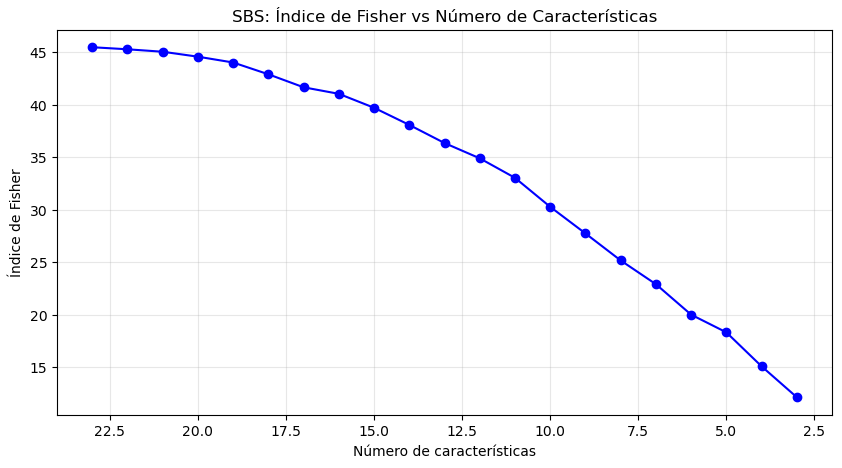

In [7]:
# graficamos Fisher vs numero de caracteristicas para ver la tendencia
n_features_list = list(range(23, 2, -1))

plt.figure(figsize=(10, 5))
plt.plot(n_features_list, historial_J, 'o-', color='blue')
plt.xlabel('Número de características')
plt.ylabel('Índice de Fisher')
plt.title('SBS: Índice de Fisher vs Número de Características')
plt.grid(alpha=0.3)
plt.gca().invert_xaxis()
plt.show()

In [8]:
# probamos con 5 valores distintos 
valores_a_probar = [20, 15, 10, 7, 5]

print('vemos como queda Fisher con distintas cantidades:\n')
print(f'{"N features":<12} {"Fisher":<12} {"Caracteristicas"}')
print('-' * 90)

for n in valores_a_probar:
    idx = 23 - n
    if 0 <= idx < len(historial_J):
        feats_str = ', '.join(historial_features[idx])
        print(f'{n:<12} {historial_J[idx]:<12.4f} {feats_str}')

vemos como queda Fisher con distintas cantidades:

N features   Fisher       Caracteristicas
------------------------------------------------------------------------------------------
20           44.5622      R_contrast, R_correlation, R_dissimilarity, R_homogeneity, R_ASM, R_energy, G_contrast, G_correlation, G_dissimilarity, G_homogeneity, G_energy, B_contrast, B_correlation, B_dissimilarity, B_homogeneity, B_energy, gray_contrast, gray_correlation, gray_dissimilarity, gray_energy
15           39.7017      R_contrast, R_correlation, R_dissimilarity, R_homogeneity, R_ASM, R_energy, G_correlation, B_contrast, B_correlation, B_dissimilarity, B_energy, gray_contrast, gray_correlation, gray_dissimilarity, gray_energy
10           30.2742      R_correlation, R_dissimilarity, R_energy, G_correlation, B_correlation, B_energy, gray_contrast, gray_correlation, gray_dissimilarity, gray_energy
7            22.9133      R_correlation, G_correlation, B_correlation, gray_contrast, gray_correlation

In [9]:
# elegimos el numero de caracteristicas
# buscamos donde el Fisher deja de bajar mucho al quitar features
# calculamos cuanto se pierde porcentualmente al eliminar cada feature
fisher_max = historial_J[0]
perdida_porcentual = [(fisher_max - j) / fisher_max * 100 for j in historial_J]

# mostramos la perdida para los 5 valores
print('cuanto Fisher se pierde en cada caso:\n')
for n in valores_a_probar:
    idx = 23 - n
    if 0 <= idx < len(perdida_porcentual):
        print(f'  con {n} features: Fisher = {historial_J[idx]:.4f}  (se pierde {perdida_porcentual[idx]:.1f}%)')

# elegimos 10 features como buen punto intermedio
# se pierde poco Fisher pero se reduce bastante la dimensionalidad
n_elegido = 10
idx_elegido = 23 - n_elegido
mejor_features = historial_features[idx_elegido]
indices_mejor = [nombres_columnas.index(f) for f in mejor_features]
X_sel = X_norm[:, indices_mejor]

print(f'\nelegimos {n_elegido} caracteristicas')
print('Fisher:', round(historial_J[idx_elegido], 4))
print('features:', list(mejor_features))
print('quedo de', X_sel.shape)

cuanto Fisher se pierde en cada caso:

  con 20 features: Fisher = 44.5622  (se pierde 2.0%)
  con 15 features: Fisher = 39.7017  (se pierde 12.7%)
  con 10 features: Fisher = 30.2742  (se pierde 33.4%)
  con 7 features: Fisher = 22.9133  (se pierde 49.6%)
  con 5 features: Fisher = 18.3318  (se pierde 59.7%)

elegimos 10 caracteristicas
Fisher: 30.2742
features: [np.str_('R_correlation'), np.str_('R_dissimilarity'), np.str_('R_energy'), np.str_('G_correlation'), np.str_('B_correlation'), np.str_('B_energy'), np.str_('gray_contrast'), np.str_('gray_correlation'), np.str_('gray_dissimilarity'), np.str_('gray_energy')]
quedo de (500, 10)


---
## Parte IV: Compresión con VQ (Vector Quantization)
Aplicamos kmeans de scipy para reducir las 500 muestras a ~100 centroides, tal como se vio en la clase 13. Luego graficamos los centroides sobre los pares de características más representativos.

In [10]:
from scipy.cluster import vq

# blanqueamos los datos (normaliza por la varianza, como en clase 13)
obs = vq.whiten(X_sel)

# aplicamos VQ con 100 centroides
n_centroides = 100
cbk, distortion = vq.kmeans(obs, n_centroides, iter=20)

print('muestras originales:', obs.shape[0])
print('centroides que salieron:', cbk.shape[0])
print('distorsion:', round(distortion, 4))

muestras originales: 500
centroides que salieron: 100
distorsion: 0.2978


In [11]:
# asignamos cada muestra original a su centroide mas cercano
asignaciones, _ = vq.vq(obs, cbk)

# le ponemos clase a cada centroide segun la clase mas comun de sus muestras
clases_centroides = []
for c in range(cbk.shape[0]):
    mask = asignaciones == c
    if np.sum(mask) > 0:
        clase_c = int(np.bincount(y[mask].astype(int)).argmax())
        clases_centroides.append(clase_c)
    else:
        clases_centroides.append(0)

clases_centroides = np.array(clases_centroides)
print('clases que quedaron en los centroides:', np.unique(clases_centroides))
print('cuantos centroides por clase:')
for clase in np.unique(clases_centroides):
    if clase > 0:
        print(f'  textura {int(clase)}: {np.sum(clases_centroides == clase)}')

clases que quedaron en los centroides: [ 1  2  3  4  5  6  7  8  9 10]
cuantos centroides por clase:
  textura 1: 8
  textura 2: 8
  textura 3: 10
  textura 4: 12
  textura 5: 12
  textura 6: 9
  textura 7: 14
  textura 8: 12
  textura 9: 7
  textura 10: 8


In [ ]:
# para graficar elegimos las 3 features mas representativas segun el SBS
# son las ultimas 3 que quedaron cuando el SBS bajo hasta 3, o sea las que
# el algoritmo considero que separan mejor las clases segun Fisher
mejores_3 = list(feature_names[indices_sel])
idx_best = [list(mejor_features).index(f) for f in mejores_3]

colores = ['red', 'blue', 'green', 'orange', 'purple',
           'brown', 'pink', 'gray', 'olive', 'cyan']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# grafico 1: mejor feature 0 vs mejor feature 1
ax = axes[0]
for clase in np.unique(y):
    mask = y == clase
    ax.scatter(obs[mask, idx_best[0]], obs[mask, idx_best[1]],
               c=colores[int(clase) - 1], s=10, alpha=0.3, label=f'Textura {int(clase)}')
for clase in np.unique(clases_centroides):
    if clase == 0:
        continue
    mask_c = clases_centroides == clase
    ax.scatter(cbk[mask_c, idx_best[0]], cbk[mask_c, idx_best[1]],
               c=colores[int(clase) - 1], marker='x', s=100, linewidths=2)

ax.set_xlabel(mejores_3[0])
ax.set_ylabel(mejores_3[1])
ax.set_title(f'{mejores_3[0]} vs {mejores_3[1]}')
ax.legend(fontsize=7, loc='best')
ax.grid(alpha=0.2)

# grafico 2: mejor feature 0 vs mejor feature 2
ax = axes[1]
for clase in np.unique(y):
    mask = y == clase
    ax.scatter(obs[mask, idx_best[0]], obs[mask, idx_best[2]],
               c=colores[int(clase) - 1], s=10, alpha=0.3, label=f'Textura {int(clase)}')
for clase in np.unique(clases_centroides):
    if clase == 0:
        continue
    mask_c = clases_centroides == clase
    ax.scatter(cbk[mask_c, idx_best[0]], cbk[mask_c, idx_best[2]],
               c=colores[int(clase) - 1], marker='x', s=100, linewidths=2)

ax.set_xlabel(mejores_3[0])
ax.set_ylabel(mejores_3[2])
ax.set_title(f'{mejores_3[0]} vs {mejores_3[2]}')
ax.legend(fontsize=7, loc='best')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

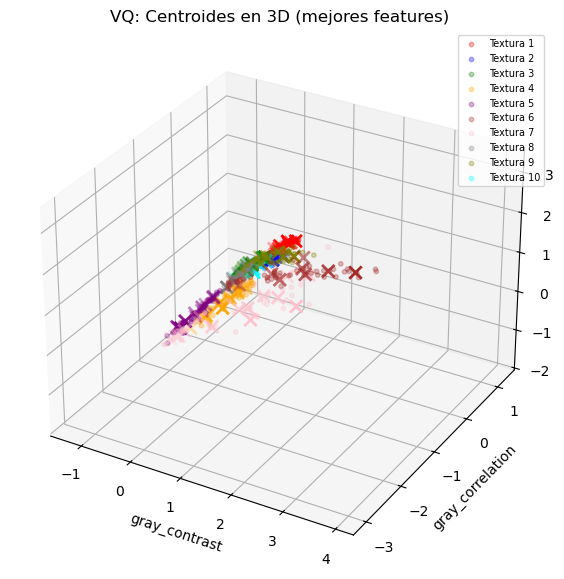

In [13]:
# grafico 3D con las 3 mejores caracteristicas
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')

for clase in np.unique(y):
    mask = y == clase
    ax.scatter(obs[mask, idx_best[0]], obs[mask, idx_best[1]], obs[mask, idx_best[2]],
               c=colores[int(clase) - 1], s=10, alpha=0.3, label=f'Textura {int(clase)}')

# centroides en 3D
for clase in np.unique(clases_centroides):
    if clase == 0:
        continue
    mask_c = clases_centroides == clase
    ax.scatter(cbk[mask_c, idx_best[0]], cbk[mask_c, idx_best[1]], cbk[mask_c, idx_best[2]],
               c=colores[int(clase) - 1], marker='x', s=80, linewidths=2)

ax.set_xlabel(mejores_3[0])
ax.set_ylabel(mejores_3[1])
ax.set_zlabel(mejores_3[2])
ax.set_title('VQ: Centroides en 3D (mejores features)')
ax.legend(fontsize=7, loc='best')
plt.show()